In [1]:
%load_ext autoreload
%autoreload 2

# Elliptic Bitcoin Fraud Detection

## Empirical Evaluation of Temporal-Structural Leakage

This notebook implements the experiment described in the proposal:

- **6 models:** Logistic Regression, XGBoost, MLP, GCN, GraphSAGE, EvolveGCN
- **2 evaluation pipelines:** random 70/10/20 split and chronological split
- **Temporal split:** train = time steps 1–34, validation = 35–39, test = 40–49
- **Primary metric:** F1, with Precision and Recall also reported
- **3 random seeds:** 42, 123, 456
- **Leakage Delta:** F1(random) − F1(temporal)
- **Additional analysis:** 49-timestep F1 curves, XGBoost feature-importance delta, GraphSAGE edge-masking ablation, and GNNExplainer subgraphs

### Important methodological rule

For the **temporal GNN experiments**, graph message passing is causal:

> A node at time `t` can only receive graph information from nodes at time `<= t`.

This prevents future graph structure from entering earlier predictions.

For feature preprocessing, the scaler is always fitted on **training nodes only**.


In [3]:
import os, sys
from dotenv import load_dotenv
import kaggle
import zipfile

project_root = os.path.abspath('./')
sys.path.insert(0, project_root)
# os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


load_dotenv()

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)
if os.path.exists(f"{DATA_DIR}/elliptic-data-set.zip"):
  print("zip file already exists, skipping download")
else:
  kaggle.api.authenticate()
  kaggle.api.dataset_download_files(dataset = "ellipticco/elliptic-data-set", path=DATA_DIR)


try:
  print("extracting data")
  file_dir = os.path.join(DATA_DIR, "elliptic-data-set.zip")
  with zipfile.ZipFile(file_dir,'r') as z:
    z.extractall(DATA_DIR)
  print("extraction done")
except Exception as e:
  print(f"something went wrong:{e}")

feature_dir = os.path.join(DATA_DIR, "elliptic_bitcoin_dataset","elliptic_txs_features.csv")
classes_dir = os.path.join(DATA_DIR, "elliptic_bitcoin_dataset","elliptic_txs_classes.csv")
edges_dir = os.path.join(DATA_DIR, "elliptic_bitcoin_dataset","elliptic_txs_edgelist.csv")
results_dir = os.path.join(DATA_DIR, "results")
figures_dir = os.path.join(DATA_DIR, "figures")

FILES = {
    "features": feature_dir,
    "classes":  classes_dir,
    "edges":    edges_dir,
}

for name, path in FILES.items():
    print(f"{name:10s}: {path}")
    print("  exists:", os.path.exists(path))

assert all(os.path.exists(p) for p in FILES.values()), (
    "Elliptic dataset files were not found. Update DATA_DIR first."
)

zip file already exists, skipping download
extracting data
extraction done
features  : data/elliptic_bitcoin_dataset/elliptic_txs_features.csv
  exists: True
classes   : data/elliptic_bitcoin_dataset/elliptic_txs_classes.csv
  exists: True
edges     : data/elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv
  exists: True


##  Load and prepare the Elliptic graph

The dataset contains:

- transaction IDs
- time steps
- 165 node features
- transaction labels
- transaction-to-transaction edges

Labels are encoded as:

- `1` = illicit
- `0` = licit
- `-1` = unknown/unlabelled


In [5]:
# ============================================================
# 1. IMPORTS AND REPRODUCIBILITY
# ============================================================


import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import networkx as nx
import matplotlib.patches as mpatches
import shutil

from torch_geometric.utils import  k_hop_subgraph
from sklearn.metrics import f1_score
from src.utils import seed_everything, get_device, build_full_graph
from src.utils import causal_edge_index
from torch_geometric.explain import Explainer, GNNExplainer



warnings.filterwarnings("ignore")



BASE_SEED = 42

seed_everything(BASE_SEED)
DEVICE = get_device()


print("PyTorch:", torch.__version__)
print("Device :", DEVICE)



# ============================================================
# 2. LOAD DATA
# ============================================================


features = pd.read_csv(FILES["features"], header=None)
features.columns = ["txId", "time_step"] + [f"feat_{i}" for i in range(1, 166)]

classes = pd.read_csv(FILES["classes"])
edges = pd.read_csv(FILES["edges"])

df = features.merge(classes, on="txId")
df["label"] = df["class"].map({"1": 1, "2": 0, "unknown": -1})

FEATURE_COLS = [c for c in df.columns if c.startswith("feat_")]

# ============================================================
# 3. BUILD THE FULL GRAPH
# ============================================================

data = build_full_graph(df, edges, FEATURE_COLS)

print(f"Nodes: {data.num_nodes:,}")
print(f"Directed message-passing edges: {data.edge_index.shape[1]:,}")

print("Nodes:", len(df))
print("Edges:", len(edges))
print("Feature count:", len(FEATURE_COLS))
print("Time steps:", df["time_step"].min(), "to", df["time_step"].max())
print("\nLabels:")
print(df["label"].value_counts().sort_index())


PyTorch: 2.10.0+cu128
Device : cuda
Nodes: 203,769
Directed message-passing edges: 468,710
Nodes: 203769
Edges: 234355
Feature count: 165
Time steps: 1 to 49

Labels:
label
-1    157205
 0     42019
 1      4545
Name: count, dtype: int64


## Leakage-safe preprocessing and the two experimental pipelines

### Random pipeline
Among labelled nodes:

- 70% training
- 10% validation
- 20% testing

This is intentionally the conventional/random baseline.

### Temporal pipeline
The chronological experiment is:

- **Train:** time steps 1–34
- **Validation:** time steps 35–39
- **Test:** time steps 40–49

The scaler is fitted only on training nodes.

For temporal GNNs, graph edges are also restricted according to time so future nodes cannot send messages backward.


In [6]:
# ============================================================
# 4. SPLITS + LEAKAGE-SAFE SCALING
# ============================================================
from src.utils import random_split, temporal_split


d_rand = random_split(data, seed=BASE_SEED)
d_temp = temporal_split(data)

print("Random:")
print(" train:", int(d_rand.train_mask.sum()))
print(" val  :", int(d_rand.val_mask.sum()))
print(" test :", int(d_rand.test_mask.sum()))

print("\nTemporal:")
print(" train: time 1–34 ->", int(d_temp.train_mask.sum()))
print(" val  : time 35–39 ->", int(d_temp.val_mask.sum()))
print(" test : time 40–49 ->", int(d_temp.test_mask.sum()))


Random:
 train: 32594
 val  : 4656
 test : 9314

Temporal:
 train: time 1–34 -> 29894
 val  : time 35–39 -> 5486
 test : time 40–49 -> 11184


# RUN THE COMPLETE EXPERIMENT

This section runs **all six models** under both pipelines for the three required seeds.

The model-specific implementations above are intentionally separated and labelled so it is easy to identify which code belongs to which architecture.


In [ ]:
# all_results accumulates one row per (model, split, seed) combination.
# artifacts keeps the seed-42 models and data objects for every later
# diagnostic (F1 curves, feature importance, ablation, GNNExplainer).

from src.utils import evaluate_predictions, seed_everything, random_split
import joblib

all_results = []
artifacts:dict = {}
SEEDS = [42, 123, 456]

In [ ]:

# ============================================================
# 5. MASTER EXPERIMENT RUNNER
# ============================================================

from src.models.logistic_regression import train_logistic_regression, predict_lr_all_nodes


for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    seed_everything(seed)

    d_rand_s = random_split(data, seed=seed)
    d_temp_s = temporal_split(data)

    # --------------------------------------------------------
    # IMPLEMENTATION FOR LOGISTIC REGRESSION
    # --------------------------------------------------------
    print("\n[LR] Random")
    lr_r, pred_r, true_r = train_logistic_regression(
        d_rand_s, seed, "random"
    )
    all_results.append(
        evaluate_predictions(true_r, pred_r, "LR", "random", seed)
    )

    print("[LR] Temporal")
    lr_t, pred_t, true_t = train_logistic_regression(
        d_temp_s, seed, "temporal"
    )
    all_results.append(
        evaluate_predictions(true_t, pred_t, "LR", "temporal", seed)
    )

    # Keep seed 42 models for the diagnostic analyses later.
    if seed == 42:
        artifacts["random"] = {"LR":lr_r}
        artifacts["temporal"] = {"LR":lr_t}
        artifacts["d_rand"] = d_rand_s
        artifacts["d_temp"] = d_temp_s

        
        joblib.dump(lr_r, "checkpoints/lr_random.joblib")
        joblib.dump(lr_t, "checkpoints/lr_temporal.joblib")

results_df = pd.DataFrame(all_results)


print("\nCompleted:", len(results_df), "model/split/seed results.")



SEED 42

[LR] Random
[LR] Temporal

SEED 123

[LR] Random
[LR] Temporal

SEED 456

[LR] Random
[LR] Temporal

Completed: 6 model/split/seed results.


In [9]:
#TRAIN XGBOOST
from src.models.xgboosts import train_xgboost,predict_xgb_all_nodes

for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    seed_everything(seed)
    
    d_rand_s = random_split(data, seed=seed)
    d_temp_s = temporal_split(data)


    print("\n[XGBoost] Random")
    xgb_r, pred_r, true_r = train_xgboost(
        d_rand_s, seed, "random"
    )
    all_results.append(
        evaluate_predictions(true_r, pred_r, "XGBoost", "random", seed)
    )

    print("[XGBoost] Temporal")
    xgb_t, pred_t, true_t = train_xgboost(
        d_temp_s, seed, "temporal"
    )
    all_results.append(
        evaluate_predictions(true_t, pred_t, "XGBoost", "temporal", seed)
    )
    
    if seed == 42:
      artifacts["random"]["XGBoost"] = xgb_r
      artifacts["temporal"]["XGBoost"] = xgb_t
      xgb_r.save_model("checkpoints/xgboost_random.json")
      xgb_t.save_model("checkpoints/xgboost_temporal.json")


SEED 42

[XGBoost] Random
[XGBoost] Temporal

SEED 123

[XGBoost] Random
[XGBoost] Temporal

SEED 456

[XGBoost] Random
[XGBoost] Temporal


In [10]:
# TRAIN MLP
from src.models.mlp import train_mlp, predict_mlp_all_nodes
for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    seed_everything(seed)

    d_rand_s = random_split(data, seed=seed)
    d_temp_s = temporal_split(data)

    print("\n[MLP] Random")
    mlp_r, pred_r, true_r = train_mlp(
        d_rand_s, seed, "random"
    )
    all_results.append(
        evaluate_predictions(true_r, pred_r, "MLP", "random", seed)
    )

    print("[MLP] Temporal")
    mlp_t, pred_t, true_t = train_mlp(
        d_temp_s, seed, "temporal"
    )
    all_results.append(
        evaluate_predictions(true_t, pred_t, "MLP", "temporal", seed)
    )

    if seed == 42:
      artifacts["random"]["MLP"] = mlp_r
      artifacts["temporal"]["MLP"] = mlp_t
      torch.save(mlp_r.state_dict(), "checkpoints/mlp_random.pt")
      torch.save(mlp_t.state_dict(), "checkpoints/mlp_temporal.pt")


SEED 42

[MLP] Random
[MLP] Temporal

SEED 123

[MLP] Random
[MLP] Temporal

SEED 456

[MLP] Random
[MLP] Temporal


In [11]:
# TRAIN GCN
from src.models.gcn_graph_sage import train_gnn, GCN

for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    seed_everything(seed)

    d_rand_s = random_split(data, seed=seed)
    d_temp_s = temporal_split(data)


    print("\n[GCN] Random")
    gcn_r, pred_r, true_r = train_gnn(
        GCN, d_rand_s, seed, "random"
    )
    all_results.append(
        evaluate_predictions(true_r, pred_r, "GCN", "random", seed)
    )

    print("[GCN] Temporal")
    gcn_t, pred_t, true_t = train_gnn(
        GCN, d_temp_s, seed, "temporal"
    )
    all_results.append(
        evaluate_predictions(true_t, pred_t, "GCN", "temporal", seed)
    )

    if seed == 42:
      artifacts["random"]["GCN"] = gcn_r
      artifacts["temporal"]["GCN"] = gcn_t
      torch.save(gcn_r.state_dict(), "checkpoints/gcn_random.pt")
      torch.save(gcn_t.state_dict(), "checkpoints/gcn_temporal.pt")


SEED 42

[GCN] Random
[GCN] Temporal

SEED 123

[GCN] Random
[GCN] Temporal

SEED 456

[GCN] Random
[GCN] Temporal


In [12]:
# TRAIN GRAPHSAGE
from src.models.gcn_graph_sage import train_gnn,GraphSAGE

for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    seed_everything(seed)

    d_rand_s = random_split(data, seed=seed)
    d_temp_s = temporal_split(data)


    print("\n[GraphSAGE] Random")
    sage_r, pred_r, true_r = train_gnn(
        GraphSAGE, d_rand_s, seed, "random"
    )
    all_results.append(
        evaluate_predictions(true_r, pred_r, "GraphSAGE", "random", seed)
    )

    print("[GraphSAGE] Temporal")
    sage_t, pred_t, true_t = train_gnn(
        GraphSAGE, d_temp_s, seed, "temporal"
    )
    all_results.append(
        evaluate_predictions(true_t, pred_t, "GraphSAGE", "temporal", seed)
    )

    if seed == 42:
      artifacts["random"]["GraphSAGE"] = sage_r
      artifacts["temporal"]["GraphSAGE"] = sage_t
      torch.save(sage_r.state_dict(), "checkpoints/graphsage_random.pt")
      torch.save(sage_t.state_dict(), "checkpoints/graphsage_temporal.pt")



SEED 42

[GraphSAGE] Random
[GraphSAGE] Temporal

SEED 123

[GraphSAGE] Random
[GraphSAGE] Temporal

SEED 456

[GraphSAGE] Random
[GraphSAGE] Temporal


In [13]:
# TRAIN EVOLVEGCN
from src.models.evolvegcn import train_evolvegcn, build_snapshots

for seed in SEEDS:
    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    seed_everything(seed)

    d_rand_s = random_split(data, seed=seed)
    d_temp_s = temporal_split(data)


    print("\n[EvolveGCN] Random")
    evo_r, pred_r, true_r = train_evolvegcn(
        d_rand_s, seed, "random"
    )
    all_results.append(
        evaluate_predictions(true_r, pred_r, "EvolveGCN", "random", seed)
    )

    print("[EvolveGCN] Temporal")
    evo_t, pred_t, true_t = train_evolvegcn(
        d_temp_s, seed, "temporal"
    )
    all_results.append(
        evaluate_predictions(true_t, pred_t, "EvolveGCN", "temporal", seed)
    )
    if seed == 42:
      artifacts["random"]["EvolveGCN"] = evo_r
      artifacts["temporal"]["EvolveGCN"] = evo_t
      torch.save(evo_r.state_dict(), "checkpoints/evolvegcn_random.pt")
      torch.save(evo_t.state_dict(), "checkpoints/evolvegcn_temporal.pt")


SEED 42

[EvolveGCN] Random
[EvolveGCN] Temporal

SEED 123

[EvolveGCN] Random
[EvolveGCN] Temporal

SEED 456

[EvolveGCN] Random
[EvolveGCN] Temporal


6. FINAL THREE-SEED SUMMARY

In [14]:
results_df = pd.DataFrame(all_results)
print("Total results collected:", len(results_df))

Total results collected: 36


In [ ]:
# ============================================================
# 6. FINAL THREE-SEED SUMMARY: MEAN ± STD
# ============================================================

summary = (
    results_df
    .groupby(["model", "split"])[["f1", "precision", "recall"]]
    .agg(["mean", "std"])
    .reset_index()
)

for metric in ["f1", "precision", "recall"]:
    summary[(metric, "std")] = summary[(metric, "std")].fillna(0)

print(summary.to_string(index=False))

results_df.to_csv(
    f"{results_dir}/all_results.csv",
    index=False
)


    model    split       f1          precision            recall         
                       mean      std      mean      std     mean      std
EvolveGCN   random 0.624720 0.050964  0.476883 0.058486 0.911622 0.005342
EvolveGCN temporal 0.147875 0.134256  0.094393 0.085722 0.341195 0.309469
      GCN   random 0.647150 0.016959  0.503628 0.020020 0.905615 0.002467
      GCN temporal 0.430518 0.023471  0.438731 0.045719 0.424004 0.004804
GraphSAGE   random 0.778015 0.015901  0.667340 0.020968 0.933002 0.010054
GraphSAGE temporal 0.468890 0.019075  0.419667 0.033580 0.533019 0.011871
       LR   random 0.603369 0.016762  0.444725 0.018613 0.938822 0.003923
       LR temporal 0.255034 0.000000  0.150452 0.000000 0.836478 0.000000
      MLP   random 0.792406 0.006619  0.686189 0.015368 0.937947 0.011391
      MLP temporal 0.242827 0.203013  0.505127 0.428988 0.399371 0.341781
  XGBoost   random 0.958978 0.002600  0.968748 0.008174 0.949471 0.006852
  XGBoost temporal 0.668814 0.003898  

In [ ]:
# ============================================================
# 7. LEAKAGE DELTA
# ============================================================
# Leakage Delta = F1(random) - F1(temporal)

f1_summary = (
    results_df
    .groupby(["model", "split"])["f1"]
    .agg(["mean", "std"])
    .reset_index()
)

random_f1 = (
    f1_summary[f1_summary["split"] == "random"]
    .rename(columns={
        "mean": "f1_random_mean",
        "std": "f1_random_std"
    })
    .drop(columns=["split"])
)

temporal_f1 = (
    f1_summary[f1_summary["split"] == "temporal"]
    .rename(columns={
        "mean": "f1_temporal_mean",
        "std": "f1_temporal_std"
    })
    .drop(columns=["split"])
)

leakage_delta = random_f1.merge(
    temporal_f1,
    on="model"
)

leakage_delta["leakage_delta"] = (
    leakage_delta["f1_random_mean"] -
    leakage_delta["f1_temporal_mean"]
)

leakage_delta["leakage_pct_of_random"] = (
    leakage_delta["leakage_delta"] /
    leakage_delta["f1_random_mean"].replace(0, np.nan) *
    100
)

leakage_delta = leakage_delta.sort_values(
    "leakage_delta",
    ascending=False
)

print(leakage_delta.to_string(index=False))

leakage_delta.to_csv(
    f"{results_dir}/leakage_delta.csv",
    index=False
)


    model  f1_random_mean  f1_random_std  f1_temporal_mean  f1_temporal_std  leakage_delta  leakage_pct_of_random
      MLP        0.792406       0.006619          0.242827         0.203013       0.549579              69.355770
EvolveGCN        0.624720       0.050964          0.147875         0.134256       0.476845              76.329377
       LR        0.603369       0.016762          0.255034         0.000000       0.348336              57.731775
GraphSAGE        0.778015       0.015901          0.468890         0.019075       0.309125              39.732501
  XGBoost        0.958978       0.002600          0.668814         0.003898       0.290164              30.257641
      GCN        0.647150       0.016959          0.430518         0.023471       0.216632              33.474738


In [ ]:
# ============================================================
# 7b. LEAKAGE DELTA — FORMATTED (mean ± std)
# ============================================================

leakage_delta_formatted = leakage_delta.copy()

leakage_delta_formatted["f1_random"] = leakage_delta_formatted.apply(
    lambda r: f"{r.f1_random_mean:.4f} ± {r.f1_random_std:.4f}", axis=1
)
leakage_delta_formatted["f1_temporal"] = leakage_delta_formatted.apply(
    lambda r: f"{r.f1_temporal_mean:.4f} ± {r.f1_temporal_std:.4f}", axis=1
)
leakage_delta_formatted["leakage_delta_fmt"] = leakage_delta_formatted.apply(
    lambda r: f"{r.leakage_delta:.4f} ({r.leakage_pct_of_random:.1f}%)", axis=1
)

display_cols = ["model", "f1_random", "f1_temporal", "leakage_delta_fmt"]

print("=" * 70)
print("  LEAKAGE DELTA TABLE  (mean ± std across 3 seeds)")
print("=" * 70)
print(leakage_delta_formatted[display_cols].to_string(index=False))

leakage_delta_formatted.to_csv(f"{results_dir}/leakage_delta_formatted.csv", index=False)

  LEAKAGE DELTA TABLE  (mean ± std across 3 seeds)
    model       f1_random     f1_temporal leakage_delta_fmt
      MLP 0.7924 ± 0.0066 0.2428 ± 0.2030    0.5496 (69.4%)
EvolveGCN 0.6247 ± 0.0510 0.1479 ± 0.1343    0.4768 (76.3%)
       LR 0.6034 ± 0.0168 0.2550 ± 0.0000    0.3483 (57.7%)
GraphSAGE 0.7780 ± 0.0159 0.4689 ± 0.0191    0.3091 (39.7%)
  XGBoost 0.9590 ± 0.0026 0.6688 ± 0.0039    0.2902 (30.3%)
      GCN 0.6471 ± 0.0170 0.4305 ± 0.0235    0.2166 (33.5%)


### Per-seed diagnostic: EvolveGCN and MLP stability

EvolveGCN and MLP showed high variance across seeds in the summary table above.
This breaks results down per seed to check whether that variance comes from
one collapsed/unstable seed or is spread evenly across all three.

In [18]:
print(results_df[results_df["model"].isin(["EvolveGCN","MLP"])].sort_values(["model","split","seed"]).to_string(index=False))

 seed     model    split       f1  precision   recall
   42 EvolveGCN   random 0.669437   0.528010 0.914345
  123 EvolveGCN   random 0.635492   0.489532 0.905467
  456 EvolveGCN   random 0.569231   0.413107 0.915054
   42 EvolveGCN temporal 0.000000   0.000000 0.000000
  123 EvolveGCN temporal 0.181509   0.115785 0.419811
  456 EvolveGCN temporal 0.262116   0.167393 0.603774
   42       MLP   random 0.784799   0.669337 0.948400
  123       MLP   random 0.795564   0.689799 0.939636
  456       MLP   random 0.796853   0.699431 0.925806
   42       MLP temporal 0.340981   0.238815 0.595912
  123       MLP temporal 0.378109   0.276565 0.597484
  456       MLP temporal 0.009390   1.000000 0.004717


## 8. F1 curves across all 49 time steps

This diagnostic shows how performance changes over time.

For temporal GNNs, the graph used at time `t` contains only information available by `t`.


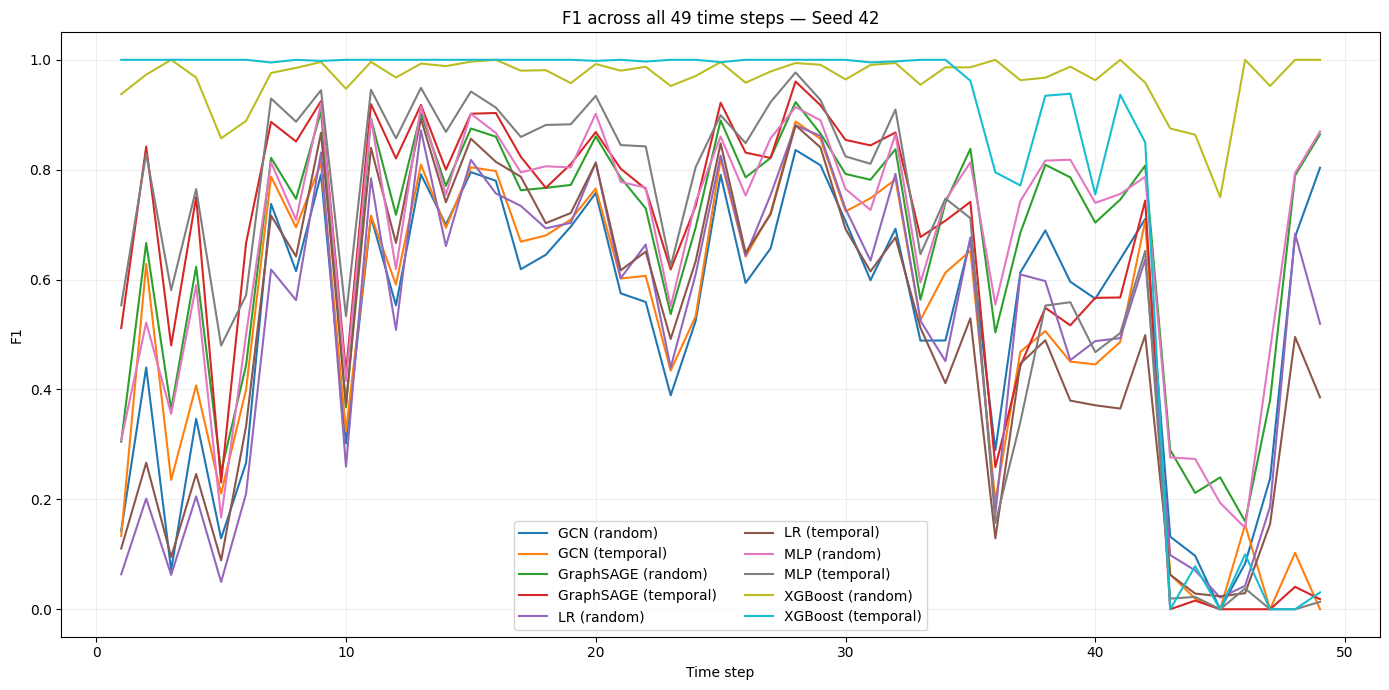

In [ ]:

# ============================================================
# 8. F1 CURVES ACROSS ALL 49 TIME STEPS
# ============================================================

def f1_by_timestep(y, pred, time_steps):
    rows = []

    y = np.asarray(y)
    pred = np.asarray(pred)
    times = np.asarray(time_steps)

    for t in range(1, 50):
        mask = (times == t) & (y != -1)

        if mask.sum() == 0:
            continue

        rows.append({
            "time_step": t,
            "f1": f1_score(
                y[mask],
                pred[mask],
                pos_label=1,
                zero_division=0
            )
        })

    return pd.DataFrame(rows)


def predict_all_nodes(model_name, model, data, split_name):
    # Non-graph models
    if model_name == "LR":
        pred = predict_lr_all_nodes(model, data)

    elif model_name == "XGBoost":
        pred = predict_xgb_all_nodes(model, data)

    elif model_name == "MLP":
        pred = predict_mlp_all_nodes(model, data)

    # Standard GNNs
    elif model_name in ["GCN", "GraphSAGE"]:
        pred = np.full(data.num_nodes, -1, dtype=np.int64)

        model.eval()

        with torch.no_grad():
            if split_name == "random":
                logits = model(
                    data.x.to(DEVICE),
                    data.edge_index.to(DEVICE)
                )
                pred = logits.argmax(1).cpu().numpy()

            else:
                for t in range(1, 50):
                    mask = data.time_step == t

                    if not mask.any():
                        continue

                    ei = causal_edge_index(data, t).to(DEVICE)

                    logits = model(
                        data.x.to(DEVICE),
                        ei
                    )

                    pred[mask.cpu().numpy()] = (
                        logits[mask.to(DEVICE)]
                        .argmax(1)
                        .cpu()
                        .numpy()
                    )

    else:
        raise ValueError("Use snapshot prediction for EvolveGCN.")

    return pred


# Seed-42 diagnostic curves
curve_rows = []

for split_name in ["random", "temporal"]:
    d = artifacts[f"d_{'rand' if split_name == 'random' else 'temp'}"]

    for model_name in [
        "LR", "XGBoost", "MLP",
        "GCN", "GraphSAGE"
    ]:
        pred = predict_all_nodes(
            model_name,
            artifacts[split_name][model_name],
            d,
            split_name
        )

        curve = f1_by_timestep(
            d.y.numpy(),
            pred,
            d.time_step.numpy()
        )

        curve["model"] = model_name
        curve["split"] = split_name
        curve_rows.append(curve)

curve_df = pd.concat(curve_rows, ignore_index=True)

plt.figure(figsize=(14, 7))

for (model, split), g in curve_df.groupby(["model", "split"]):
    plt.plot(
        g["time_step"],
        g["f1"],
        label=f"{model} ({split})"
    )

plt.xlabel("Time step")
plt.ylabel("F1")
plt.title("F1 across all 49 time steps — Seed 42")
plt.legend(ncol=2)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    f"{figures_dir}/f1_all_models_49_timesteps.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


### EvolveGCN: timestep predictions

EvolveGCN is sequential, so its predictions are generated by advancing the recurrent graph state through the ordered snapshots.


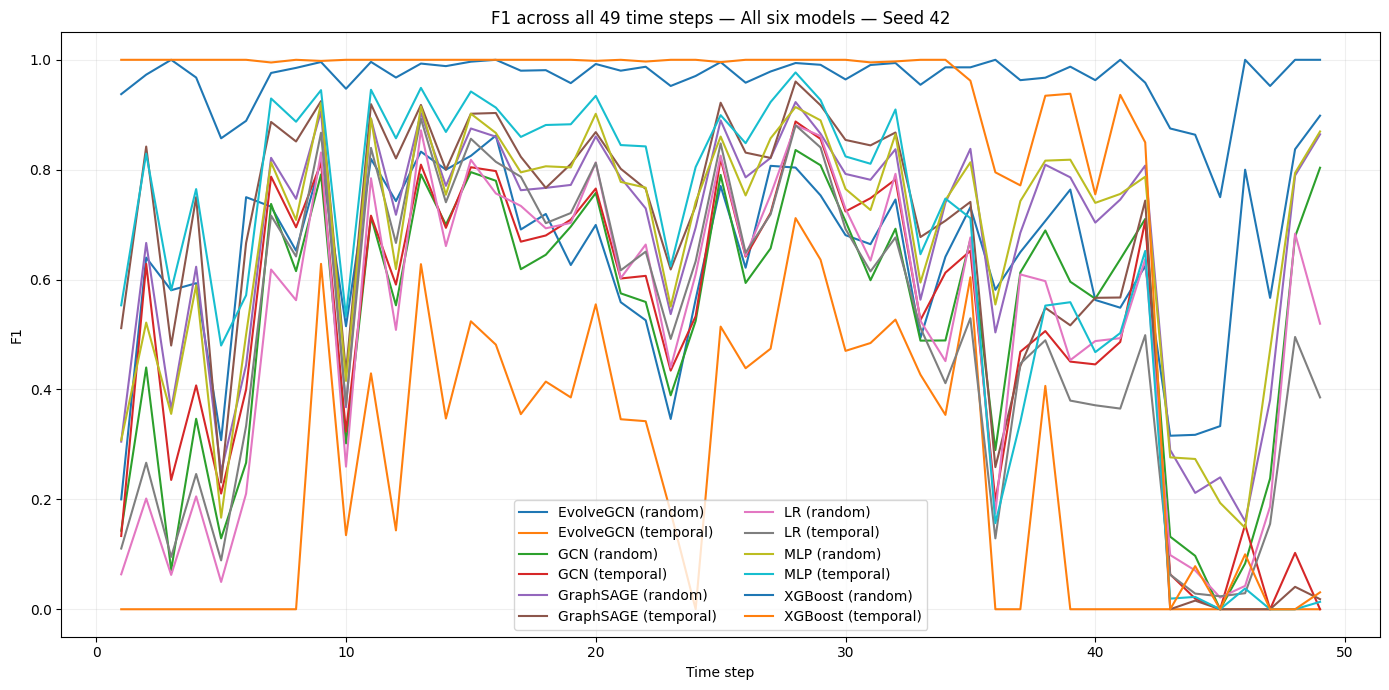

In [ ]:
# ============================================================
# 8b.EVOLVEGCN — F1 ACROSS ALL 49 TIME STEPS
# ============================================================

def evolvegcn_f1_by_timestep(model, data):
    model = model.to(DEVICE).eval()
    snapshots = build_snapshots(data)

    model.reset_state()

    rows = []

    with torch.no_grad():
        for snap in snapshots:
            t = snap["time"]

            x = snap["x"].to(DEVICE)
            ei = snap["edge_index"].to(DEVICE)

            logits = model(x, ei)
            pred = logits.argmax(1).cpu().numpy()
            true = snap["y"].numpy()

            mask = true != -1

            if mask.sum() > 0:
                rows.append({
                    "time_step": t,
                    "f1": f1_score(
                        true[mask],
                        pred[mask],
                        pos_label=1,
                        zero_division=0
                    )
                })

    return pd.DataFrame(rows)


evo_curve_rows = []

for split_name in ["random", "temporal"]:
    d = artifacts[f"d_{'rand' if split_name == 'random' else 'temp'}"]

    curve = evolvegcn_f1_by_timestep(
        artifacts[split_name]["EvolveGCN"],
        d
    )

    curve["model"] = "EvolveGCN"
    curve["split"] = split_name
    evo_curve_rows.append(curve)

evo_curve_df = pd.concat(
    evo_curve_rows,
    ignore_index=True
)

curve_df = pd.concat(
    [curve_df, evo_curve_df],
    ignore_index=True
)

plt.figure(figsize=(14, 7))

for (model, split), g in curve_df.groupby(["model", "split"]):
    plt.plot(
        g["time_step"],
        g["f1"],
        label=f"{model} ({split})"
    )

plt.xlabel("Time step")
plt.ylabel("F1")
plt.title("F1 across all 49 time steps — All six models — Seed 42")
plt.legend(ncol=2)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    f"{figures_dir}/f1_all_six_models_49_timesteps.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


## 9. XGBoost feature-importance delta

This analysis is intentionally described as a **Seed-42 diagnostic**.

It compares XGBoost feature importance between the random and temporal experiments:

`importance_delta = random_importance − temporal_importance`

A large positive delta means a feature is more important under the random evaluation.


Top 20 features by random-minus-temporal importance:
feat_14     0.060976
feat_5      0.051986
feat_65     0.049302
feat_46     0.017772
feat_60     0.013948
feat_58     0.009715
feat_49     0.009593
feat_29     0.009268
feat_90     0.009117
feat_31     0.008726
feat_160    0.007257
feat_127    0.007108
feat_1      0.005591
feat_125    0.005156
feat_163    0.005049
feat_67     0.004449
feat_10     0.004444
feat_77     0.004422
feat_154    0.004276
feat_146    0.003944
dtype: float32


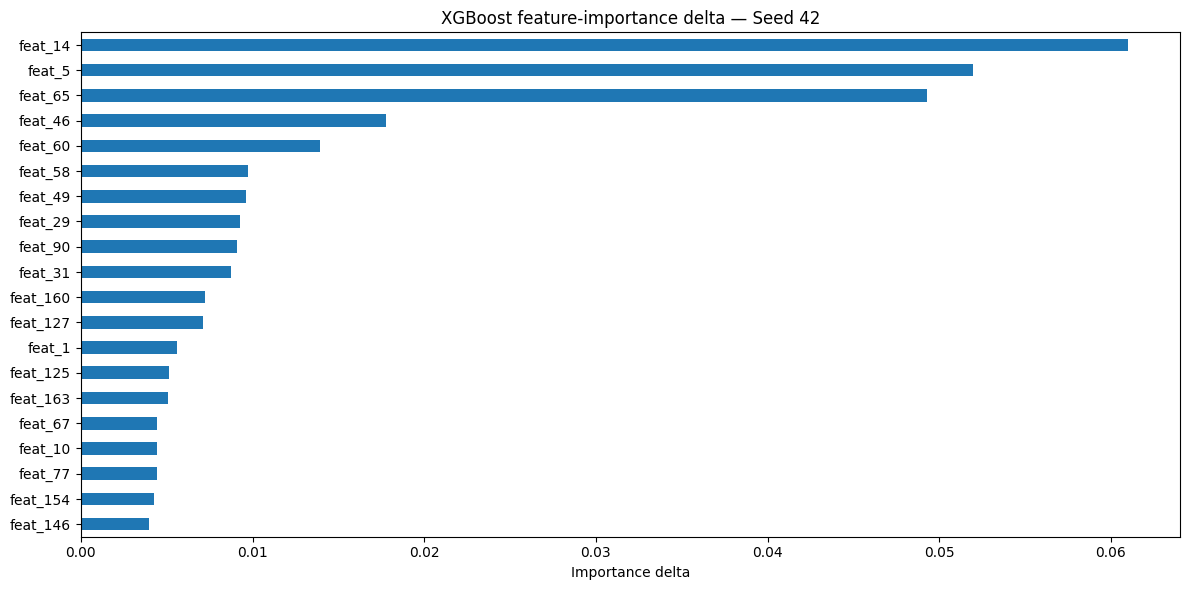

In [ ]:
# ============================================================
# 9. FEATURE-IMPORTANCE DELTA
# ============================================================

xgb_random = artifacts["random"]["XGBoost"]
xgb_temporal = artifacts["temporal"]["XGBoost"]

importance_random = pd.Series(
    xgb_random.feature_importances_,
    index=FEATURE_COLS
)

importance_temporal = pd.Series(
    xgb_temporal.feature_importances_,
    index=FEATURE_COLS
)

importance_delta = (
    importance_random - importance_temporal
).sort_values(ascending=False)

print("Top 20 features by random-minus-temporal importance:")
print(importance_delta.head(20))

plt.figure(figsize=(12, 6))
importance_delta.head(20).sort_values().plot(kind="barh")
plt.xlabel("Importance delta")
plt.title(
    "XGBoost feature-importance delta — Seed 42"
)
plt.tight_layout()
plt.savefig(
    f"{figures_dir}/feature_importance_delta.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


Avg importance delta — local features (1-94)         : 0.000443
Avg importance delta — neighbourhood features (95-165): -0.000586


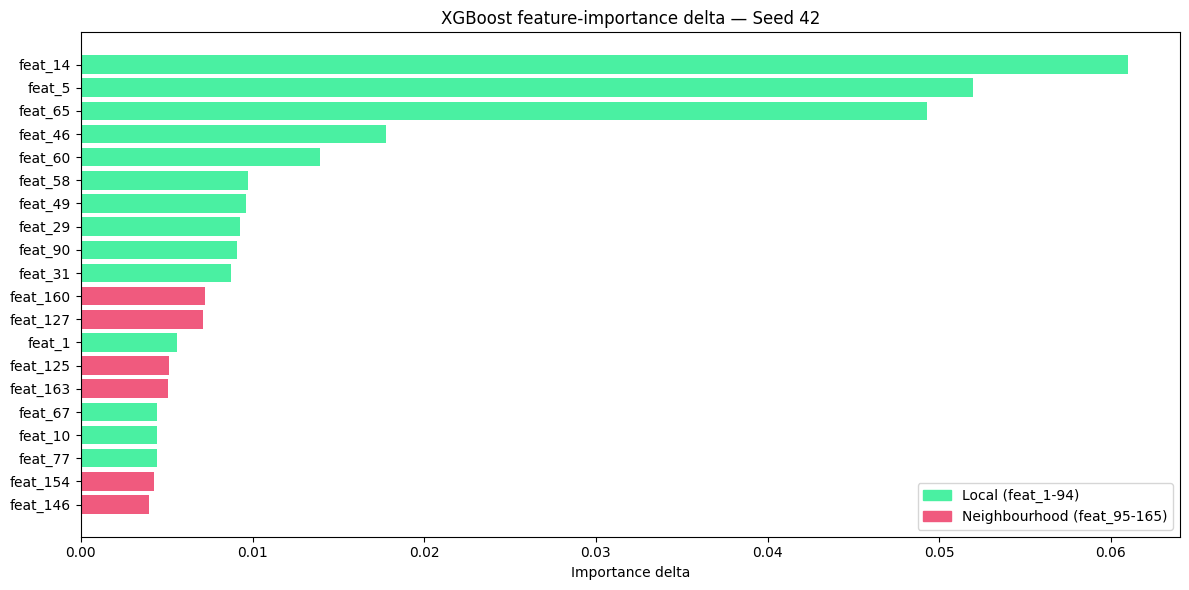

In [ ]:
# ============================================================
# 9b. FEATURE-IMPORTANCE DELTA — LOCAL VS NEIGHBOURHOOD
# ============================================================

def feat_num(name):
    return int(name.split("_")[1])

local_delta = importance_delta[[f for f in importance_delta.index if feat_num(f) <= 94]]
neigh_delta = importance_delta[[f for f in importance_delta.index if feat_num(f) > 94]]

print(f"Avg importance delta — local features (1-94)         : {local_delta.mean():.6f}")
print(f"Avg importance delta — neighbourhood features (95-165): {neigh_delta.mean():.6f}")

top20_sorted = importance_delta.head(20).sort_values()

local_color = "#4af0a2"
neigh_color = "#f05a7e"
colors = [local_color if feat_num(f) <= 94 else neigh_color for f in top20_sorted.index]

plt.figure(figsize=(12, 6))
plt.barh(top20_sorted.index, top20_sorted.values, color=colors)
plt.xlabel("Importance delta")
plt.title("XGBoost feature-importance delta — Seed 42")

local_patch = mpatches.Patch(color=local_color, label="Local (feat_1-94)")
neigh_patch = mpatches.Patch(color=neigh_color, label="Neighbourhood (feat_95-165)")
plt.legend(handles=[local_patch, neigh_patch], loc="lower right")

plt.tight_layout()
plt.savefig(f"{figures_dir}/feature_importance_delta_grouped.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. GraphSAGE edge-masking ablation

This experiment removes an increasing percentage of **undirected edge pairs**.

It asks:

> How dependent is the GraphSAGE model on graph structure?

Important: removing 100% of the original edges does **not** make GraphSAGE literally equivalent to an MLP because the layer still has its root/self transformation.


In [ ]:
# ============================================================
# 10. EDGE-MASKING ABLATION
# ============================================================

def remove_undirected_edges(data, pct_remove, seed=42):
    d = data.clone()

    src = d.edge_index[0].cpu().numpy()
    dst = d.edge_index[1].cpu().numpy()

    # Treat A->B and B->A as one undirected pair.
    a = np.minimum(src, dst)
    b = np.maximum(src, dst)

    pair_key = a.astype(np.int64) * d.num_nodes + b.astype(np.int64)

    unique_pairs, first_indices = np.unique(
        pair_key,
        return_index=True
    )

    rng = np.random.default_rng(seed)

    keep_count = int(
        len(unique_pairs) * (1 - pct_remove)
    )

    kept_pair_indices = rng.choice(
        len(unique_pairs),
        size=keep_count,
        replace=False
    )

    kept_pairs = set(
        unique_pairs[kept_pair_indices].tolist()
    )

    keep_mask = np.array(
        [key in kept_pairs for key in pair_key]
    )

    d.edge_index = d.edge_index[
        :,
        torch.tensor(keep_mask, dtype=torch.bool)
    ]

    return d


def quick_graphsage_f1(data, split_name, seed=42, epochs=75):
    model, pred, true = train_gnn(
        GraphSAGE,
        data,
        seed,
        split_name,
        epochs=epochs
    )

    return f1_score(
        true,
        pred,
        pos_label=1,
        zero_division=0
    )


ablation_rows = []

for pct in [0.0, 0.25, 0.50, 0.75, 1.0]:
    print(f"Removing {int(pct*100)}% of edge pairs...")

    d_r = remove_undirected_edges(
        artifacts["d_rand"],
        pct,
        seed=42
    )

    d_t = remove_undirected_edges(
        artifacts["d_temp"],
        pct,
        seed=42
    )

    f1_r = quick_graphsage_f1(
        d_r, "random", seed=42
    )

    f1_t = quick_graphsage_f1(
        d_t, "temporal", seed=42
    )

    ablation_rows.append({
        "edges_removed_pct": int(pct * 100),
        "f1_random": f1_r,
        "f1_temporal": f1_t,
        "leakage_delta": f1_r - f1_t
    })

ablation_df = pd.DataFrame(ablation_rows)

print(ablation_df)

ablation_df.to_csv(
    f"{results_dir}/edge_masking_ablation.csv",
    index=False
)


Removing 0% of edge pairs...
Removing 25% of edge pairs...
Removing 50% of edge pairs...
Removing 75% of edge pairs...
Removing 100% of edge pairs...
   edges_removed_pct  f1_random  f1_temporal  leakage_delta
0                  0   0.704412     0.352546       0.351867
1                 25   0.682497     0.337178       0.345319
2                 50   0.672440     0.315079       0.357360
3                 75   0.645872     0.285614       0.360258
4                100   0.643994     0.263484       0.380510


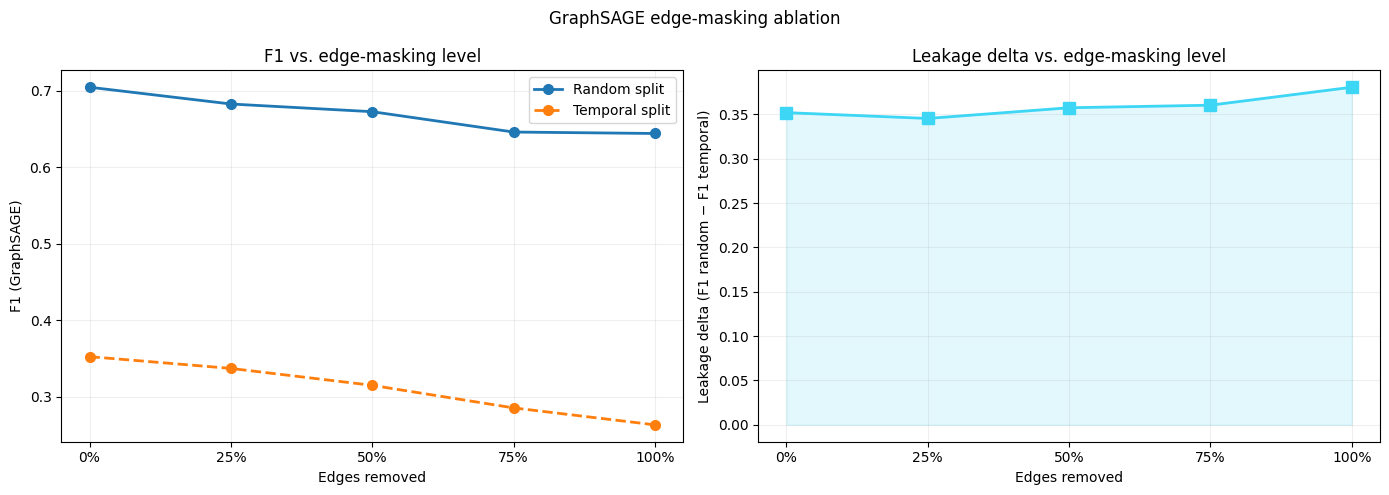

In [ ]:
# ============================================================
# 10b. EDGE-MASKING ABLATION — PLOTS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_labels = [f"{r}%" for r in ablation_df["edges_removed_pct"]]
x = range(len(x_labels))

axes[0].plot(x, ablation_df["f1_random"], "o-", linewidth=2, markersize=7, label="Random split")
axes[0].plot(x, ablation_df["f1_temporal"], "o--", linewidth=2, markersize=7, label="Temporal split")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(x_labels)
axes[0].set_xlabel("Edges removed")
axes[0].set_ylabel("F1 (GraphSAGE)")
axes[0].set_title("F1 vs. edge-masking level")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(x, ablation_df["leakage_delta"], "s-", linewidth=2, markersize=8, color="#3dd6f5")
axes[1].fill_between(x, ablation_df["leakage_delta"], alpha=0.15, color="#3dd6f5")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(x_labels)
axes[1].set_xlabel("Edges removed")
axes[1].set_ylabel("Leakage delta (F1 random − F1 temporal)")
axes[1].set_title("Leakage delta vs. edge-masking level")
axes[1].grid(alpha=0.2)

plt.suptitle("GraphSAGE edge-masking ablation")
plt.tight_layout()
plt.savefig(f"{figures_dir}/edge_masking_ablation_plot.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. GNNExplainer subgraph visualisations

The explanation is generated for local neighbourhoods rather than the entire 203k-node graph.

The examples are selected from the temporal test period and can be used to illustrate:

- a correctly detected illicit node (TP)
- an illicit node missed by the model (FN)

The graph shown is a local explanatory subgraph.


In [25]:
# ============================================================
# 11. GNNEXPLAINER SUBGRAPH VISUALISATIONS
# ============================================================

def explain_node_with_gnnexplainer(
    model,
    data,
    node_idx,
    time_step,
    hops=2
):
    model = model.to(DEVICE).eval()
    d = data.to(DEVICE)

    causal_edges = causal_edge_index(d, time_step).to(DEVICE)

    subset, sub_edge_index, mapping, edge_mask = k_hop_subgraph(
        node_idx,
        hops,
        causal_edges,
        relabel_nodes=True
    )

    sub_x = d.x[subset]

    # Explain the model on the local subgraph.
    explainer = Explainer(
        model=model,
        algorithm=GNNExplainer(epochs=100),
        explanation_type="model",
        node_mask_type="attributes",
        edge_mask_type="object",
        model_config=dict(
            mode="multiclass_classification",
            task_level="node",
            return_type="raw"
        )
    )

    explanation = explainer(
        x=sub_x,
        edge_index=sub_edge_index,
        index=int(mapping)
    )

    return subset.cpu(), sub_edge_index.cpu(), explanation, int(mapping)


def draw_explanation(
    subset,
    edge_index,
    explanation,
    target_node,
    output_path,
    title
):
    graph = nx.Graph()

    edges_np = edge_index.numpy()

    if explanation.edge_mask is not None:
        edge_scores = explanation.edge_mask.detach().cpu().numpy()
        threshold = np.quantile(edge_scores, 0.75)
    else:
        edge_scores = np.ones(edges_np.shape[1])
        threshold = 0

    for i, (src, dst) in enumerate(edges_np.T):
        if edge_scores[i] >= threshold:
            graph.add_edge(
                int(src),
                int(dst),
                weight=float(edge_scores[i])
            )

    if target_node not in graph:
        graph.add_node(target_node)

    pos = nx.spring_layout(
        graph,
        seed=42
    )

    plt.figure(figsize=(8, 7))

    nx.draw_networkx_nodes(
        graph,
        pos,
        node_size=450
    )

    nx.draw_networkx_edges(
        graph,
        pos,
        width=1.5
    )

    nx.draw_networkx_labels(
        graph,
        pos,
        font_size=8
    )

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(
        output_path,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()


In [26]:
d_temp = artifacts["d_temp"]
model = artifacts["temporal"]["GraphSAGE"]
model.eval()

with torch.no_grad():
    logits = model(d_temp.x.to(DEVICE), causal_edge_index(d_temp, 49).to(DEVICE))
    preds = logits.argmax(1).cpu().numpy()

test_idx = d_temp.test_mask.cpu().nonzero(as_tuple=True)[0].numpy()
y_true = d_temp.y.cpu().numpy()

tp_candidates = [i for i in test_idx if y_true[i] == 1 and preds[i] == 1]
fn_candidates = [i for i in test_idx if y_true[i] == 1 and preds[i] == 0]

print("TP example node:", tp_candidates[0] if tp_candidates else "none found")
print("FN example node:", fn_candidates[0] if fn_candidates else "none found")
print("time_step of TP:", int(d_temp.time_step[tp_candidates[0]]) if tp_candidates else None)
print("time_step of FN:", int(d_temp.time_step[fn_candidates[0]]) if fn_candidates else None)

TP example node: 157325
FN example node: 157211
time_step of TP: 40
time_step of FN: 40


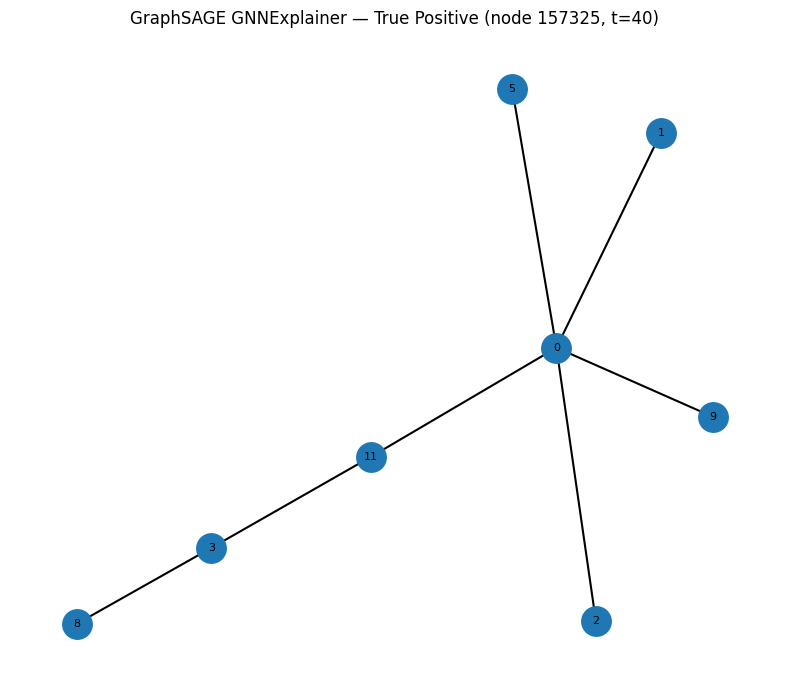

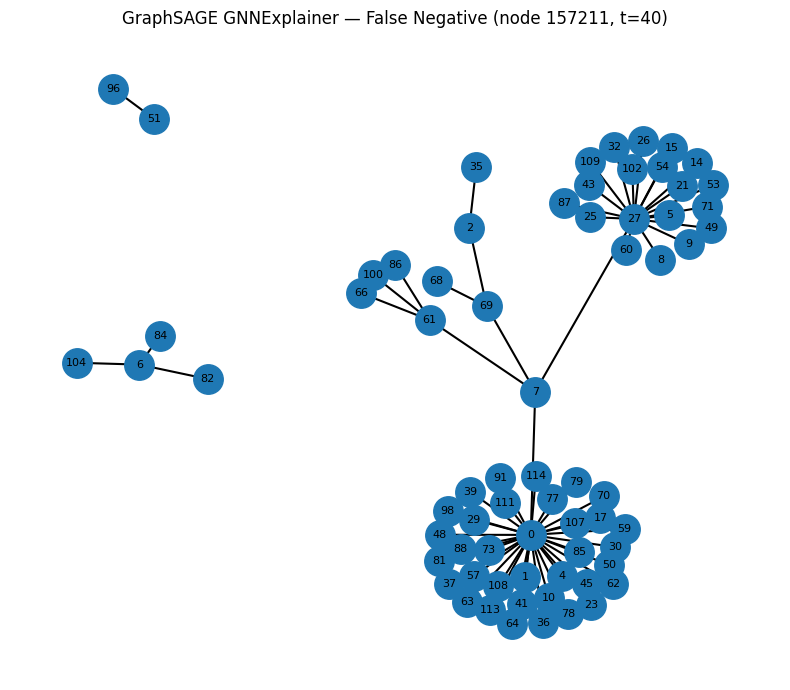

In [ ]:
# --- True Positive: node 157325, time_step 40 ---
SUBSET_TP, SUB_EDGES_TP, EXPLANATION_TP, TARGET_TP = explain_node_with_gnnexplainer(
    artifacts["temporal"]["GraphSAGE"],
    artifacts["d_temp"],
    157325,
    time_step=40
)

draw_explanation(
    SUBSET_TP,
    SUB_EDGES_TP,
    EXPLANATION_TP,
    target_node=TARGET_TP,
    output_path=f"{figures_dir}/gnnexplainer_TP_157325.png",
    title="GraphSAGE GNNExplainer — True Positive (node 157325, t=40)"
)

# --- False Negative: node 157211, time_step 40 ---
SUBSET_FN, SUB_EDGES_FN, EXPLANATION_FN, TARGET_FN = explain_node_with_gnnexplainer(
    artifacts["temporal"]["GraphSAGE"],
    artifacts["d_temp"],
    157211,
    time_step=40
)

draw_explanation(
    SUBSET_FN,
    SUB_EDGES_FN,
    EXPLANATION_FN,
    target_node=TARGET_FN,
    output_path=f"{figures_dir}/gnnexplainer_FN_157211.png",
    title="GraphSAGE GNNExplainer — False Negative (node 157211, t=40)"
)

# 12. Final outputs

The main outputs required by the proposal are:

1. **Three-seed F1 / Precision / Recall table**
2. **Leakage Delta table**
3. **F1 curves across all 49 time steps**
4. **Feature-importance delta**
5. **Graph edge-masking ablation**
6. **GNNExplainer subgraph visualisations**

Before using the numbers in the final report, run the complete notebook from top to bottom so every result is generated from the same corrected implementation.


In [ ]:
# ============================================================
# 12. SAVE FINAL TABLES
# ============================================================

results_df.to_csv(
    f"{results_dir}/final_three_seed_results.csv",
    index=False
)

leakage_delta.to_csv(
    f"{results_dir}/final_leakage_delta.csv",
    index=False
)

curve_df.to_csv(
    f"{results_dir}/f1_by_timestep_seed42.csv",
    index=False
)

print("Saved final tables to data/")
print(" - final_three_seed_results.csv")
print(" - final_leakage_delta.csv")
print(" - f1_by_timestep_seed42.csv")


Saved final tables to data/
 - final_three_seed_results.csv
 - final_leakage_delta.csv
 - f1_by_timestep_seed42.csv


In [29]:
# Zip checkpoints/ and data/ into single downloadable files for the
# supplementary material submission.

shutil.make_archive("checkpoints", "zip", "checkpoints")
print("done")

done


In [30]:
shutil.make_archive("data_output", "zip", "data")
print("done")

done


## Interpretation reminder

The central research question is **not simply which model has the highest random-split F1**.

The key comparison is:

> **How much does performance change when the evaluation is made temporally realistic?**

The headline quantity is:

$$
\text{Leakage Delta}
=
F1_{random}
-
F1_{temporal}
$$

A large positive delta indicates that the model's performance is substantially lower when it is evaluated without future temporal information.
